# Wine Quality Dataset – Linear Algebra and Probability

**Module assignment**

This notebook applies basic data preprocessing, vector extraction, covariance matrices, eigen decomposition, and probability/distribution analysis to the supplied red wine quality dataset.

> Dataset note: The uploaded file contains **1,599 rows and 12 columns** and is the **red wine** dataset (`winequality-red.csv`), not a combined red-and-white dataset.


## 1. Import libraries and load the dataset

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the supplied CSV file
df = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values by column:")
print(df.isnull().sum())

Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


\nMissing values by column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [3]:
## 2. Handle missing values.

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].mean())

print("Missing values after imputation:", df.isnull().sum().sum())

Missing values after imputation: 0


## 3. Extract alcohol and citric acid as vectors

A vector is a one-dimensional collection of numerical values. Each vector below contains one value for every wine sample.

In [7]:
alcohol_vector = df["alcohol"].to_numpy()
citric_acid_vector = df["citric acid"].to_numpy()

print("Alcohol vector shape:", alcohol_vector.shape)
print("Citric acid vector shape:", citric_acid_vector.shape)
print("First 10 alcohol values:", alcohol_vector[:10])
print("First 10 citric acid values:", citric_acid_vector[:10])

Alcohol vector shape: (1599,)
Citric acid vector shape: (1599,)
First 10 alcohol values: [ 9.4  9.8  9.8  9.8  9.4  9.4  9.4 10.   9.5 10.5]
First 10 citric acid values: [0.   0.   0.04 0.56 0.   0.   0.06 0.   0.02 0.36]


## 4. Covariance matrix for alcohol and density

Create a two-feature matrix `X` and calculate its covariance matrix using `np.cov(X.T)`. The diagonal values are the variances; the off-diagonal values are the covariance between the two features.

In [8]:
selected_features = df[["alcohol", "density"]]
X = selected_features.to_numpy()

covariance_matrix = np.cov(X.T)
print("Feature order: alcohol, density")
print(covariance_matrix)

Feature order: alcohol, density
[[ 1.13564740e+00 -9.97951790e-04]
 [-9.97951790e-04  3.56202945e-06]]


## 5. Eigen decomposition

Eigenvalues indicate the amount of variance represented along their corresponding eigenvector directions. Sort eigenvalues from largest to smallest and keep the corresponding eigenvectors in the same order.

In [9]:
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

# Sort from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Top two eigenvalues:")
print(eigenvalues[:2])

print("\\nCorresponding eigenvectors (columns):")
print(eigenvectors[:, :2])

Top two eigenvalues:
[1.13564827e+00 2.68507580e-06]
\nCorresponding eigenvectors (columns):
[[-9.99999614e-01 -8.78753184e-04]
 [ 8.78753184e-04 -9.99999614e-01]]


### Visualize the eigenvalues

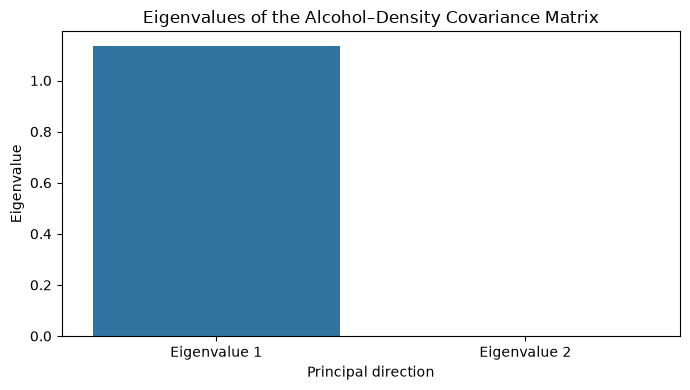

In [10]:
plt.figure(figsize=(7, 4))
sns.barplot(x=["Eigenvalue 1", "Eigenvalue 2"], y=eigenvalues)
plt.title("Eigenvalues of the Alcohol–Density Covariance Matrix")
plt.ylabel("Eigenvalue")
plt.xlabel("Principal direction")
plt.tight_layout()
plt.show()

### Interpretation

The first eigenvalue is much larger than the second. Its eigenvector is almost entirely aligned with the alcohol axis, meaning that most of the variance in this **unstandardized** two-feature covariance matrix comes from alcohol. The second direction is almost aligned with density.

The variables use different numerical scales, so alcohol's larger variance dominates. Standardizing the features before PCA would be appropriate if the goal were to compare their relative contributions on an equal scale.

## 6. Most common wine quality and probability distribution

Use value counts to identify the most frequent quality score. The relative frequency is the empirical probability of observing each quality score in this dataset.

Most common quality score: 5
\nQuality counts:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64
\nEmpirical probabilities:
quality
3     0.63%
4     3.31%
5    42.59%
6     39.9%
7    12.45%
8     1.13%
Name: proportion, dtype: str


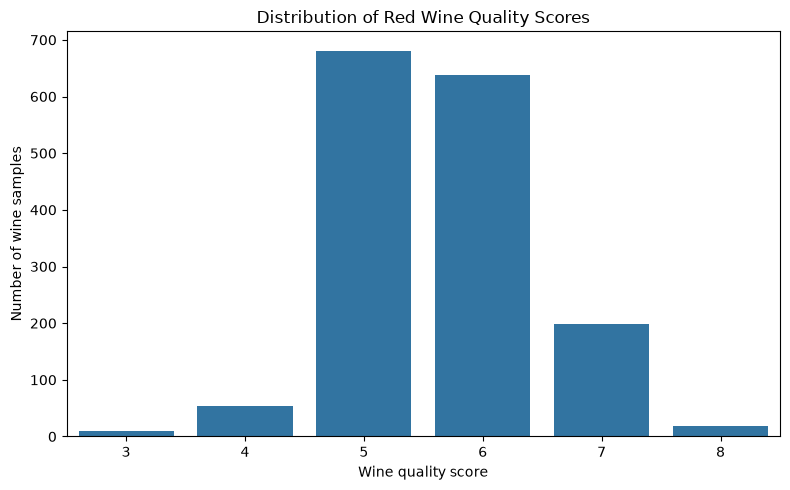

In [11]:
quality_counts = df["quality"].value_counts().sort_index()
quality_probabilities = df["quality"].value_counts(normalize=True).sort_index()

most_common_quality = df["quality"].mode()[0]
print("Most common quality score:", most_common_quality)
print("\\nQuality counts:")
print(quality_counts)
print("\\nEmpirical probabilities:")
print((quality_probabilities * 100).round(2).astype(str) + "%")

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", order=sorted(df["quality"].unique()))
plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Wine quality score")
plt.ylabel("Number of wine samples")
plt.tight_layout()
plt.show()

## 7. Data story and conclusions

- The dataset contains 1,599 red wine samples and 12 columns.
- Missing-value imputation was applied to numeric columns; the supplied file has no missing values, so no values needed to be replaced.
- `alcohol` and `citric acid` were extracted as one-dimensional vectors, each containing 1,599 observations.
- The covariance matrix was calculated for `alcohol` and `density`.
- The largest eigenvalue is associated with a direction that is almost entirely the alcohol axis. This reflects the much larger raw variance of alcohol compared with density; it does not by itself prove a strong relationship between the variables.
- Quality score **5** is the most common, followed by score **6**. Together, these account for most observations. Scores at the low and high ends are relatively uncommon.
- The quality distribution is concentrated around scores 5 and 6 rather than being evenly distributed.

### Important interpretation note
Covariance and eigenvalues depend on feature scales. For a scale-neutral principal component analysis, standardize the selected features first. Also, the empirical probabilities describe this dataset and should not automatically be treated as probabilities for every wine population.